# Rủi ro tín dụng Freddie Mac vintage 2019
Notebook đọc ba mart trong PostgreSQL `analytics.serving`, không đọc dữ liệu khoản vay cá nhân. Chạy `make run-all` trước, rồi `make notebook`.

Tỷ lệ theo tháng dùng số khoản vay đang hoạt động; loại `XX` khỏi mẫu số quá hạn. Không cộng dư nợ qua nhiều tháng. Tên bên bán/servicer có nhóm `OTHER`; nhóm này không đại diện một tổ chức duy nhất. Gold giữ nhóm điểm/LTV/DTI theo phiên bản tại tháng báo cáo; CORR1 không viết lại lịch sử các tháng cũ.


In [1]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
import psycopg2
from IPython.display import display
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'conf/pipeline.yml').is_file())
env = {}
for line in (root / '.env').read_text().splitlines():
    if line and not line.startswith('#') and '=' in line:
        key, value = line.split('=', 1)
        env[key.strip()] = value.strip()

NOTEBOOK_DATASET = "sample"
NOTEBOOK_PG_PORT = "5432"

def query(sql):
    with psycopg2.connect(host=os.environ.get('NOTEBOOK_PG_HOST', '127.0.0.1'),
                         port=NOTEBOOK_PG_PORT, dbname='analytics',
                         user=env['POSTGRES_USER'], password=env['POSTGRES_PASSWORD']) as conn:
        with conn.cursor() as cur:
            cur.execute(sql)
            return pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])

publication = query("SELECT dataset, ready FROM control.gold_publication")
assert publication.loc[publication.dataset == NOTEBOOK_DATASET, 'ready'].any(), 'Chưa có Gold hợp lệ cho dataset này'
d = query('SELECT * FROM serving.mart_delinquency')
p = query('SELECT * FROM serving.mart_prepayment ORDER BY reporting_date')
c = query('SELECT * FROM serving.mart_covid_forbearance')
assert not d.empty and not p.empty
for frame in (d, p, c):
    if 'reporting_date' in frame:
        frame['reporting_date'] = pd.to_datetime(frame['reporting_date'])
    for column in frame:
        if column.endswith(('_upb', '_rate')) or column in ('smm', 'cpr'):
            frame[column] = pd.to_numeric(frame[column])

print("Nguồn:", NOTEBOOK_DATASET, "| Số tháng đã nạp:", p.reporting_date.nunique(),
      "| Từ", p.reporting_date.min().date(), "đến", p.reporting_date.max().date())

def plot_rates(group, title):
    sums = d.groupby(group)[['eligible_count', 'd30_count', 'd60_count', 'd90_plus_count']].sum()
    rates = sums[['d30_count', 'd60_count', 'd90_plus_count']].div(sums.eligible_count.replace(0, float('nan')), axis=0)
    ax = rates.plot(figsize=(11, 4), title=title)
    ax.set_ylabel('Tỷ lệ khoản vay'); plt.tight_layout(); plt.show()
    return rates


Nguồn: sample | Số tháng đã nạp: 87 | Từ 2019-01-01 đến 2026-03-01


## 1. Quá hạn thay đổi thế nào, nhất là COVID 2020–2021?
Biểu đồ thể hiện ba nhóm loại trừ nhau: 30–59, 60–89 và 90+ ngày. Phải cộng tử số/mẫu số trước khi chia, không lấy trung bình các tỷ lệ của từng nhóm.

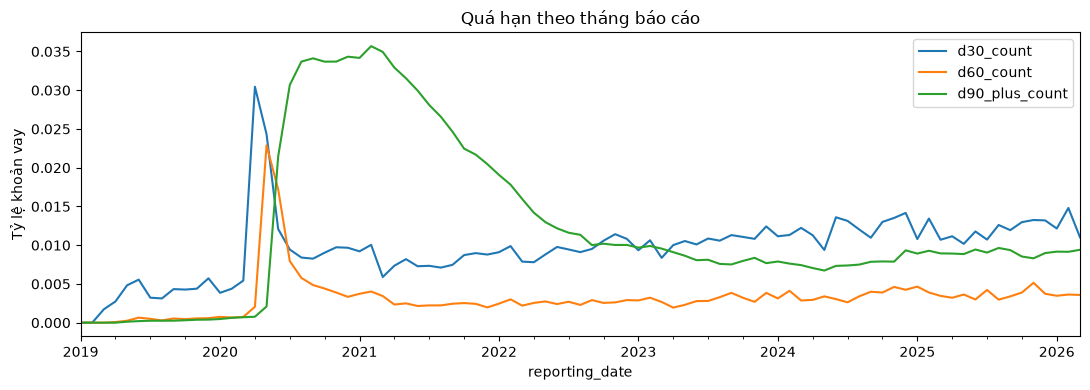

,d30_count,d60_count,d90_plus_count
mean,0.009643,0.004439,0.023727
max,0.030449,0.022892,0.035687


In [2]:
monthly = plot_rates('reporting_date', 'Quá hạn theo tháng báo cáo')
display(monthly.loc['2020-01-01':'2021-12-01'].agg(['mean', 'max']))

## 2. Điểm tín dụng, LTV và DTI liên hệ với quá hạn ra sao?
Đây là tương quan mô tả, không chứng minh quan hệ nhân quả. Biểu đồ gộp các tháng nên mẫu số là số lần quan sát khoản vay–tháng.

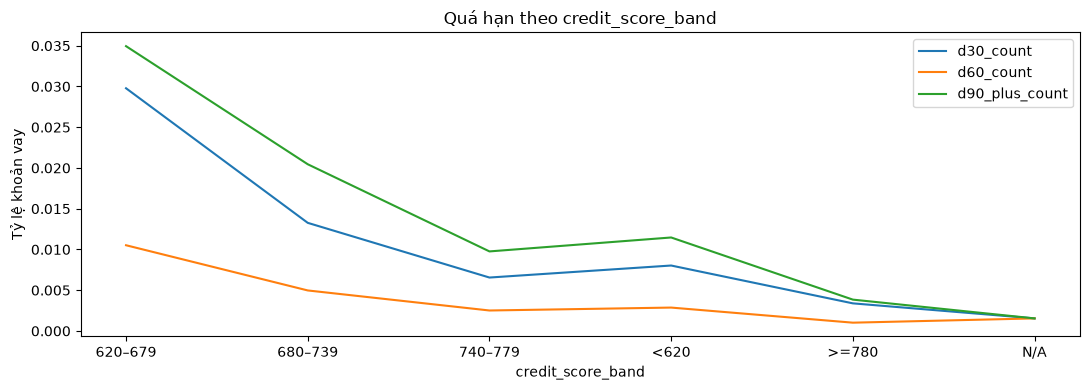

,d30_count,d60_count,d90_plus_count
credit_score_band,,,
620–679,0.029778,0.010516,0.034945
680–739,0.013264,0.004969,0.020454
740–779,0.006553,0.002509,0.009758
<620,0.008028,0.002867,0.011468
>=780,0.003385,0.001015,0.003843
N/A,0.001538,0.001538,0.001538


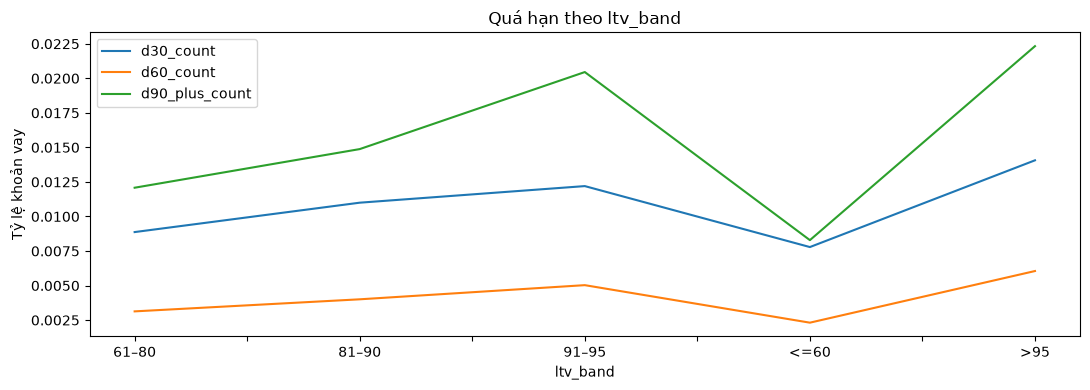

,d30_count,d60_count,d90_plus_count
ltv_band,,,
61–80,0.008871,0.003132,0.012081
81–90,0.010998,0.004005,0.014877
91–95,0.012199,0.005029,0.020452
<=60,0.007787,0.002314,0.008288
>95,0.014065,0.006052,0.022327


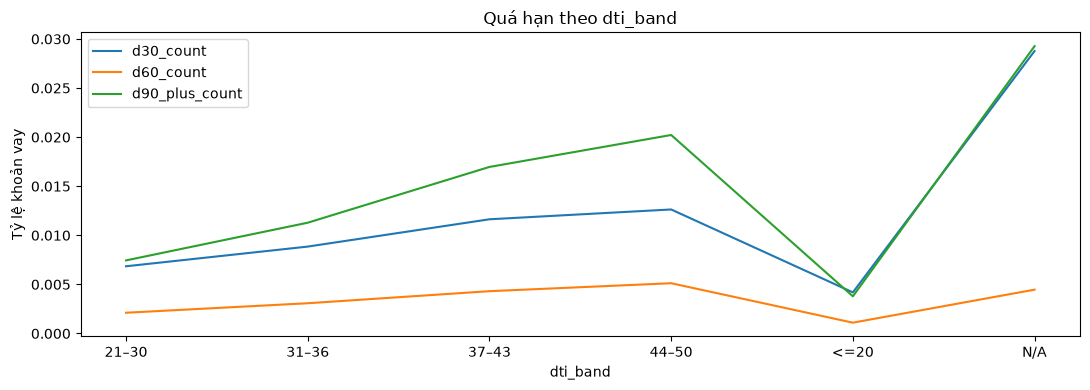

,d30_count,d60_count,d90_plus_count
dti_band,,,
21–30,0.006846,0.002113,0.007444
31–36,0.008851,0.003080,0.011285
37–43,0.011632,0.004308,0.016964
44–50,0.012632,0.005119,0.020218
<=20,0.004186,0.001101,0.003787
N/A,0.028770,0.004464,0.029266


In [3]:
for band in ('credit_score_band', 'ltv_band', 'dti_band'):
    display(plot_rates(band, 'Quá hạn theo ' + band))

## 3. Bang và bên bán nào có tỷ lệ 90+ cao?
Hiện 10 nhóm có tỷ lệ cao nhất và mẫu số ít nhất 100 khoản vay–tháng để hạn chế nhóm quá nhỏ.

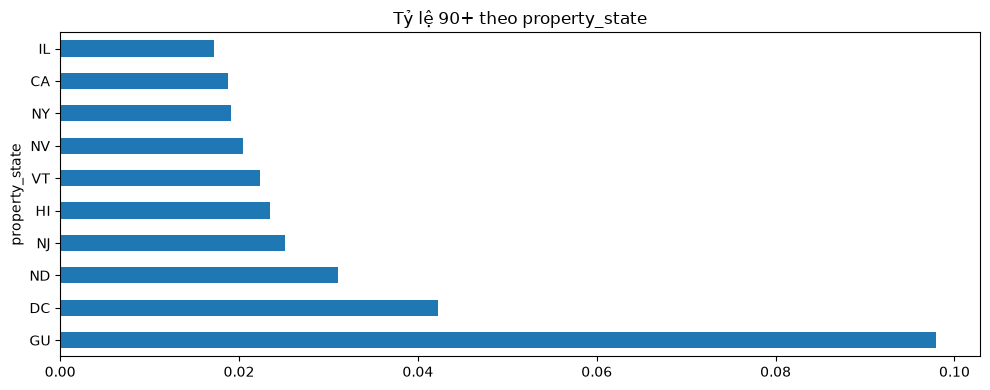

,eligible_count,d90_plus_count,rate
property_state,,,
GU,490,48,0.097959
DC,3506,148,0.042213
ND,3990,124,0.031078
NJ,53123,1337,0.025168
HI,5324,125,0.023479
VT,5192,116,0.022342
NV,25044,511,0.020404
NY,74887,1434,0.019149
CA,176229,3311,0.018788


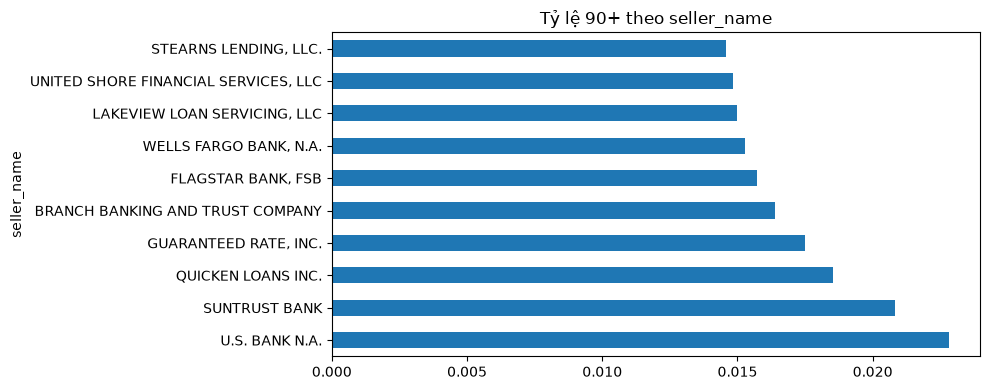

,eligible_count,d90_plus_count,rate
seller_name,,,
U.S. BANK N.A.,71933,1642,0.022827
SUNTRUST BANK,27241,567,0.020814
QUICKEN LOANS INC.,128571,2381,0.018519
"GUARANTEED RATE, INC.",22333,391,0.017508
BRANCH BANKING AND TRUST COMPANY,30935,507,0.016389
"FLAGSTAR BANK, FSB",35263,555,0.015739
"WELLS FARGO BANK, N.A.",161724,2469,0.015267
"LAKEVIEW LOAN SERVICING, LLC",12019,180,0.014976
"UNITED SHORE FINANCIAL SERVICES, LLC",120936,1796,0.014851


In [4]:
for group in ('property_state', 'seller_name'):
    sums = d.groupby(group)[['eligible_count', 'd90_plus_count']].sum()
    sums['rate'] = sums.d90_plus_count / sums.eligible_count.replace(0, float('nan'))
    top = sums[sums.eligible_count >= 100].nlargest(10, 'rate')
    top.rate.plot.barh(title='Tỷ lệ 90+ theo ' + group, figsize=(10, 4)); plt.tight_layout(); plt.show()
    display(top)

## 4. Hoãn trả COVID và kết cục sau đó
Cohort có ít nhất một tháng F trong 202003–202112. Xét 12 tháng sau tháng F cuối cùng; ưu tiên vỡ nợ, trả trước, sửa đổi; sau đó hồi phục nếu đúng hạn ở cuối cửa sổ. `UNKNOWN` biểu thị không đủ quan sát để kết luận. Đây là phân tích kết cục dùng dữ liệu tương lai, không phải đặc trưng dự báo tại thời điểm hoãn trả.

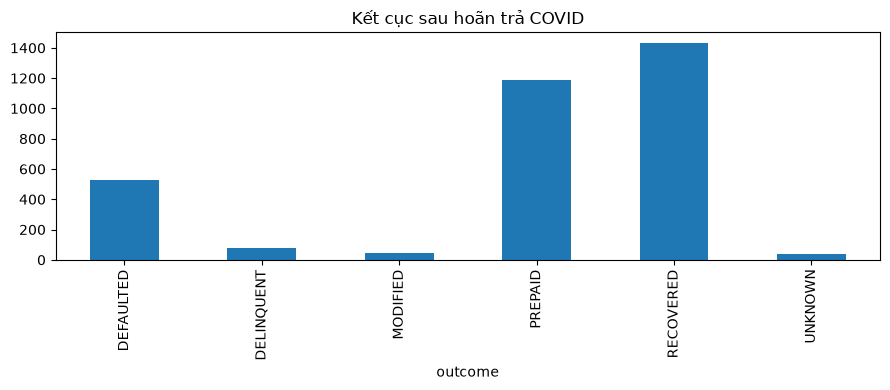

,loan_count
outcome,
DEFAULTED,524
DELINQUENT,80
MODIFIED,44
PREPAID,1191
RECOVERED,1431
UNKNOWN,40


Tổng cohort: 3310


In [5]:
if c.empty:
    print('Chưa có quan sát cohort COVID trong các kỳ đã nạp.')
else:
    outcomes = c.groupby('outcome').loan_count.sum()
    outcomes.plot.bar(title='Kết cục sau hoãn trả COVID', figsize=(9, 4)); plt.tight_layout(); plt.show()
    display(outcomes.to_frame()); print('Tổng cohort:', int(outcomes.sum()))


## 5. Tỷ lệ trả trước hạn thay đổi thế nào?
SMM = dư nợ xóa sổ do trả trước tháng m / dư nợ hoạt động tháng m−1; CPR = 1 − (1 − SMM)^12. Tháng đầu thiếu mẫu số được giữ null. Dữ liệu không có lý do trả trước; không thể khẳng định một khoản vay trả trước do tái cấp vốn.

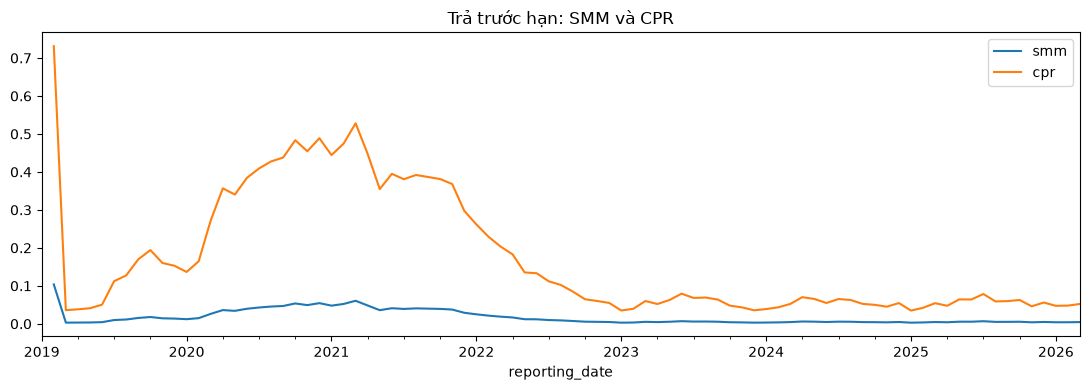

,reporting_date,prepaid_count,smm,cpr
75,2025-04-01,78,0.004043,0.047447
76,2025-05-01,107,0.005521,0.064272
77,2025-06-01,97,0.005500,0.064036
78,2025-07-01,117,0.006782,0.078413
79,2025-08-01,87,0.005046,0.058900
80,2025-09-01,92,0.005119,0.059727
81,2025-10-01,95,0.005386,0.062757
82,2025-11-01,70,0.003921,0.046046
83,2025-12-01,91,0.004791,0.056003
84,2026-01-01,69,0.004033,0.047336


In [6]:
p.set_index('reporting_date')[['smm', 'cpr']].plot(title='Trả trước hạn: SMM và CPR', figsize=(11, 4))
plt.tight_layout(); plt.show()
display(p[['reporting_date', 'prepaid_count', 'smm', 'cpr']].tail(12))